#COU 07506 Digital signal Processing - Week 01:Lab 0 setting Up the DSP Laboratory

Name:Gilbert Steven Ngonyani
Registration N: 240242444701
Class: BENG24COE    Group:             Date:24 Novenber 2026
Instrucor Checkpoints signed:  

##Pre-Lab

Three devices I Used today that contain DSP,and One signal each processes:

1.Mobile Phone: Processes speech(voice) signals during calls.
2.Headphones: Processe music(Audio) signals.
3.Wi-Fi router:Processes radio frequency signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] =(9, 3.5)

In [2]:
n=np.arange(-5, 11)
delta=(n==0).astype(float)     #unit impluse
step=(n>=0).astype(float)      #unit step
ramp=n*step                    #unit ramp
expo=0.8**n*step               #real exponential

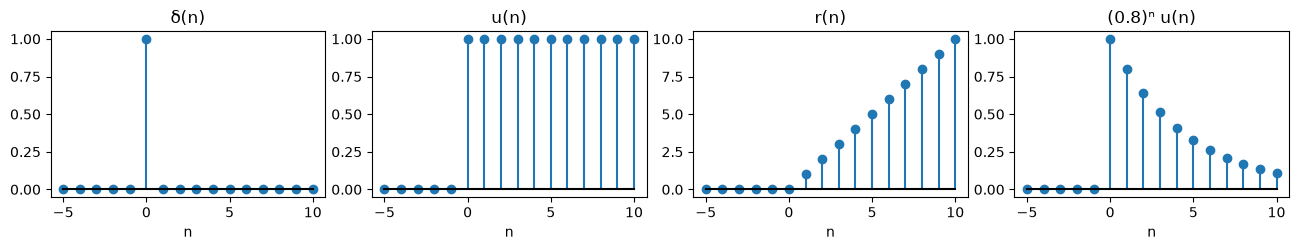

In [3]:
fig, axes=plt.subplots(1,4, figsize=(13,2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                         ["δ(n)", "u(n)", "r(n)", "(0.8)ⁿ u(n)"]):
    ax.stem(n,x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

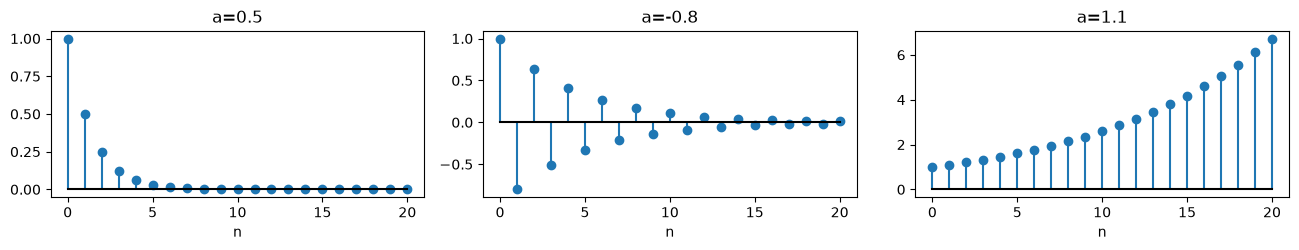

In [4]:
n=np.arange(0,21)
step=(n>=0).astype(float)

fig, axes=plt.subplots(1,3, figsize=(13,2.6))
for ax,a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n * step, basefmt="k-")
    ax.set_title(f"a={a}")
    ax.set_xlabel("n")
    ax.set_xlabel("n")

plt.tight_layout(); plt.show()

**observation 9task 1.2, part 10;88 for a = 0.5 the sequence decays quICKLY TO ZERO> FOR A + _)>* IT DECAYS SLOWLY WHILE ALTERNATING IN SIGN> FOR A + !>! IT GROWS WITHOUT BOUND>

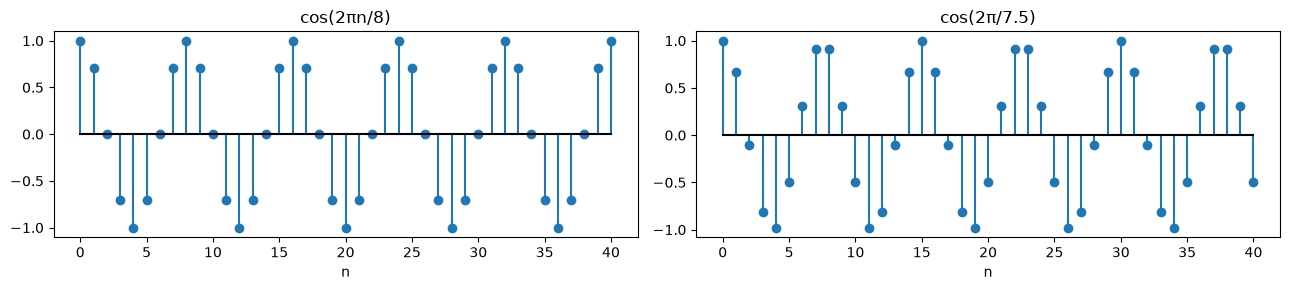

In [5]:
n=np.arange(0,41)

fig, axes=plt.subplots(1,2,figsize=(13,3))
axes[0].stem(n,np.cos(2*np.pi*n/8), basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[1].stem(n,np.cos(2*np.pi*n/7.5), basefmt="k-")
axes[1].set_title("cos(2π/7.5)")
for ax in axes:
    ax.set_xlabel("n")
plt.tight_layout(); plt.show()

**answer (task 1.2, part 2); cos(2n/8) repeats exactly every 8 samples because 2/ = 8 is an integer. cos92n/7.50 does not repeat exactly, because its period 97.5 samples0 is not an interger. 

## Task 1.3 - Working with Audio

fs=48000Hz, duration=6.78 s,samples=325632


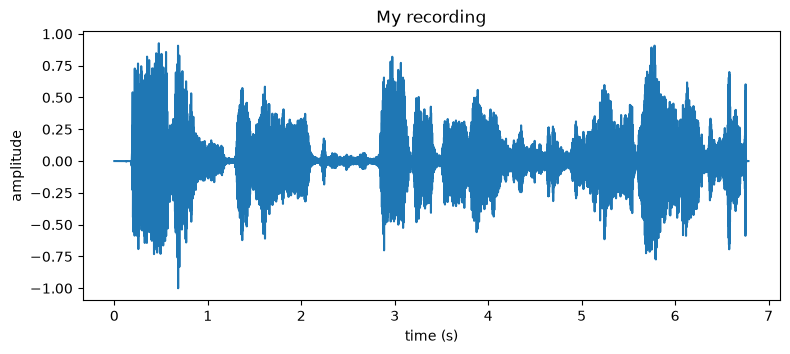

In [6]:
import os
fname="my_voice.wav"
if os.path.exists(fname):
    fs, x=wavfile.read(fname)
    if x.ndim>1:                     #stereo ->mono
        x=x.mean(axis=1)
    x=x/np.max(np.abs(x))            #normalise to [-1,1]
else:                                #fallback test signal
    fs=16000
    t=np.arange(0,2,1/fs)
    x=0.5*np.sin(2*np.pi*440*t)*np.exp(-t)

t=np.arange(len(x)) /fs
print(f"fs={fs}Hz, duration={len(x)/fs:.2f} s,samples={len(x)}")
plt.plot(t,x)
plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()


In [7]:
from IPython.display import Audio
Audio(x, rate=fs)

##Analysis questions
**Question 1:**The sampling rate of my phone recordingis 48000Hz (48KHz
  To store one minute of it in mono,
  48000 times 60=2880000 numbers are needed

**Question 2:**A stem plot is more appropiate because x(n) is defined only at interger values of n.
  There are no values between samples,So  a stem plot shows each sample as a separate point 
  while a continous line would wronglysuggest that the signal has values between the samples, as if it were an analog signal

**Question 3:**The implus  response (1,1)ⁿ u(n) grows without bound, so it violates stability property(BIBO stability)
               A stsble systemrequire the sum of|h(n)| to be finite, but  for a=1.1 the sum diverges.Such system would produce an unbounded outputeven for a bounded input. The sequences with |a|<1(a=0.5 and a=-0.8) decay to zero and arestable.

## AI-use statement
**AI tools used :**Claude (Anthropic chat assistant)
**Used for:*Eplaining the lab tasks, setting up the Python Environmenton kali Linux, explaining what each line of the code does, and fixing typing errors(for example set title and figsize)in task 1.1 to 1.3.
Also used for understand the analysis questions.

**How i veryfied the output:**I ran every cell myself and compared the plots with the expected resultsin the lab manual(Task 1.1 sequences, Task 1.2plots)>
For  Task 1.3, I checked that the printed duration matches samples/fs(325633 / 48000=6.78s).

I comfirm that i understsnd and can explain all submitted code.